# Bangkok CCTV: Visual Dataset Exploration

This notebook reads the existing image manifest, its summary, and camera CSV. It does not rebuild the manifest, alter images, or run detection. Run cells in order with the project's Python environment.

**Counts describe image availability, not traffic volume.** Filename timestamps are treated as local clock labels without assigning or converting a timezone. The spatial plot is a coordinate scatter, not a street map. Image checks cover a reproducible sample, not every file.

## 1. Dataset Overview

In [1]:
from pathlib import Path
import json
import logging

import pandas as pd
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")
SEED = 42
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True})

def find_project_root(start: Path) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if ((candidate / "pyproject.toml").is_file()
                and (candidate / "src/bangkok_cctv").is_dir()):
            return candidate
    raise FileNotFoundError("Run from the project root or its notebooks directory.")

ROOT = find_project_root(Path.cwd())
manifest_path = ROOT / "data/interim/image_manifest.parquet"
summary_path = ROOT / "data/interim/image_manifest_summary.json"
csv_path = ROOT / "data/raw/cctv_info.csv"
for path in (manifest_path, summary_path, csv_path):
    if not path.is_file():
        raise FileNotFoundError(f"Required existing input missing: {path}")

manifest = pd.read_parquet(manifest_path)
saved_summary = json.loads(summary_path.read_text(encoding="utf-8"))
metadata = pd.read_csv(csv_path, dtype={"camera_id": "string"})
required = {"camera_id", "timestamp", "image_path", "location", "latitude", "longitude"}
if required - set(manifest.columns):
    raise ValueError(f"Manifest missing columns: {sorted(required - set(manifest.columns))}")
manifest["camera_id"] = manifest["camera_id"].astype("string")
metadata["camera_id"] = metadata["camera_id"].str.strip()
manifest["timestamp"] = pd.to_datetime(manifest["timestamp"], errors="coerce")
if manifest.empty:
    raise ValueError("The saved manifest is empty.")
print(f"Project root: {ROOT}")
print(f"Manifest shape: {manifest.shape}")
display(manifest.head(3))
display(manifest.dtypes.astype(str).rename("dtype").to_frame())
display(manifest.isna().sum().rename("missing_values").to_frame())

Project root: D:\01University\dsde-project
Manifest shape: (61319, 12)


,camera_id,timestamp,image_path,location,location_detail,location_en,location_detail_en,latitude,longitude,ip_address,image_count,metadata_matched
0,1028,2026-08-25 06:10:12,data/raw/cctv_images/cctv_images/1028/1028_แยก...,แยกสะพานแดง,แยกสะพานแดง,Red Bridge Intersection,Red Bridge Intersection,13.79343,100.52996,10.102.128.34,611,True
1,1028,2026-08-25 06:21:00,data/raw/cctv_images/cctv_images/1028/1028_แยก...,แยกสะพานแดง,แยกสะพานแดง,Red Bridge Intersection,Red Bridge Intersection,13.79343,100.52996,10.102.128.34,611,True
2,1028,2026-08-25 06:31:15,data/raw/cctv_images/cctv_images/1028/1028_แยก...,แยกสะพานแดง,แยกสะพานแดง,Red Bridge Intersection,Red Bridge Intersection,13.79343,100.52996,10.102.128.34,611,True


,dtype
camera_id,string
timestamp,datetime64[us]
image_path,str
location,str
location_detail,str
location_en,str
location_detail_en,str
latitude,float64
longitude,float64
ip_address,str


,missing_values
camera_id,0
timestamp,0
image_path,0
location,0
location_detail,0
location_en,614
location_detail_en,1228
latitude,0
longitude,0
ip_address,0


In [2]:
overview = pd.Series({
    "images": len(manifest),
    "cameras": manifest["camera_id"].nunique(),
    "first_timestamp": manifest["timestamp"].min(),
    "last_timestamp": manifest["timestamp"].max(),
    "unique_dates": manifest["timestamp"].dt.date.nunique(),
    "saved_summary_image_count_matches": len(manifest) == saved_summary["total_images"],
}, name="value")
display(overview.to_frame())

,value
images,61319
cameras,100
first_timestamp,2026-08-25 06:00:00
last_timestamp,2026-08-31 21:01:19
unique_dates,7
saved_summary_image_count_matches,True


## 2. Temporal Exploration

Counts measure available snapshots. Weekday/weekend totals are also normalized by the number of observed dates because this dataset contains unequal numbers of weekday and weekend dates.

A gap above **30 minutes** (three nominal 10-minute intervals) is flagged for inspection. This is an exploratory threshold, not proof of a collection failure. Gaps crossing dates are shown separately because overnight breaks can be intentional.

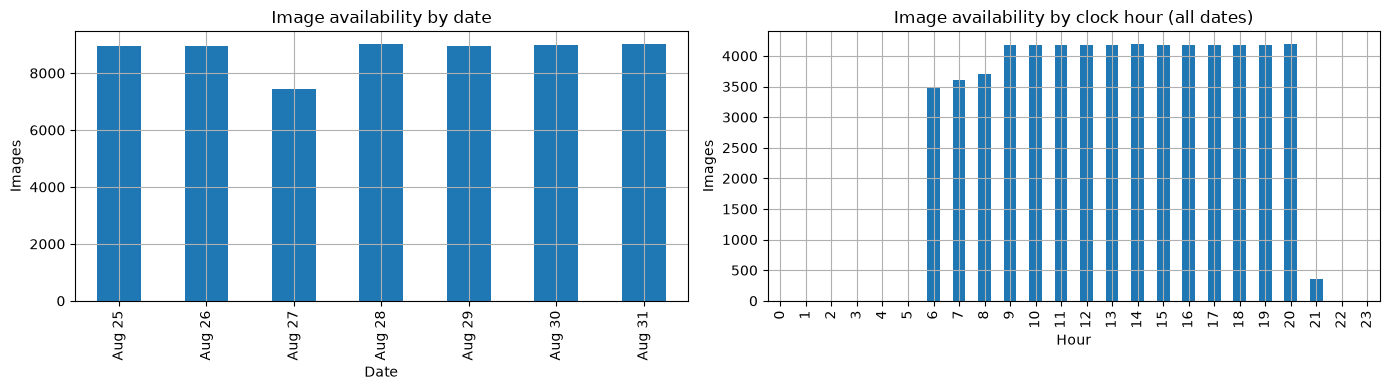

,images
date,
2026-08-25,8937
2026-08-26,8953
2026-08-27,7438
2026-08-28,9015
2026-08-29,8964
2026-08-30,9002
2026-08-31,9010


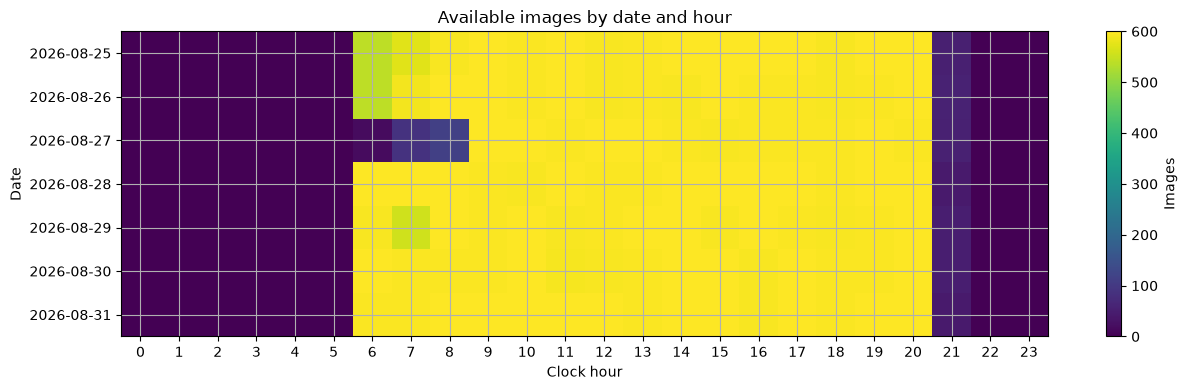

In [3]:
timed = manifest.dropna(subset=["timestamp"]).copy()
timed["date"] = timed["timestamp"].dt.normalize()
timed["hour"] = timed["timestamp"].dt.hour
daily_counts = timed.groupby("date").size().rename("images")
hour_counts = timed.groupby("hour").size().reindex(range(24), fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
daily_counts.set_axis(daily_counts.index.strftime("%b %d")).plot.bar(ax=axes[0])
axes[0].set(title="Image availability by date", xlabel="Date", ylabel="Images")
hour_counts.plot.bar(ax=axes[1])
axes[1].set(title="Image availability by clock hour (all dates)",
            xlabel="Hour", ylabel="Images")
fig.tight_layout()
display(fig)
plt.close(fig)
display(daily_counts.to_frame())

coverage = timed.pivot_table(index="date", columns="hour", values="image_path",
                            aggfunc="count", fill_value=0).reindex(columns=range(24), fill_value=0)
fig, ax = plt.subplots(figsize=(13, 4))
heat = ax.imshow(coverage.to_numpy(), aspect="auto", cmap="viridis")
ax.set(xticks=range(24), yticks=range(len(coverage)),
       yticklabels=coverage.index.strftime("%Y-%m-%d"),
       xlabel="Clock hour", ylabel="Date", title="Available images by date and hour")
fig.colorbar(heat, ax=ax, label="Images")
fig.tight_layout()
display(fig)
plt.close(fig)

,interval_minutes
count,61219.000000
mean,15.570062
std,54.629835
min,7.116667
25%,9.983333
50%,10.000000
75%,10.016667
max,715.000000


,count,min,median,mean,max
camera_id,,,,,
1028,610,8.016667,10.0,15.615956,709.950000
1039,614,8.966667,10.0,15.529126,629.966667
1060,613,7.133333,10.0,15.539505,619.983333
1063,612,8.450000,10.0,15.579929,709.983333
1070,612,7.733333,10.0,15.564924,709.983333
...,...,...,...,...,...
88,608,7.816667,10.0,15.675548,715.000000
913,609,9.700000,10.0,15.632211,630.050000
915,612,8.450000,10.0,15.563753,630.050000


Gaps >30 minutes: 671; within the same date: 71; crossing dates: 600


,camera_id,previous_timestamp,timestamp,interval_minutes,same_date
3855,1076,2026-08-26 20:56:04,2026-08-27 08:51:04,715.000000,False
58441,88,2026-08-26 20:55:36,2026-08-27 08:50:36,715.000000,False
5682,1103,2026-08-26 20:55:47,2026-08-27 08:50:46,714.983333,False
6906,112,2026-08-26 20:55:39,2026-08-27 08:50:38,714.983333,False
9359,119,2026-08-26 20:55:49,2026-08-27 08:50:48,714.983333,False
11188,123,2026-08-26 20:55:49,2026-08-27 08:50:48,714.983333,False
12412,125,2026-08-26 20:55:49,2026-08-27 08:50:48,714.983333,False
26544,1815,2026-08-26 20:55:44,2026-08-27 08:50:43,714.983333,False
43080,371,2026-08-26 20:55:37,2026-08-27 08:50:36,714.983333,False
44310,411,2026-08-26 20:55:26,2026-08-27 08:50:25,714.983333,False


,camera_id,previous_timestamp,timestamp,interval_minutes
35118,233,2026-08-27 07:25:15,2026-08-27 09:00:13,94.966667
1405,1060,2026-08-27 07:21:21,2026-08-27 08:51:22,90.016667
7519,1132,2026-08-27 07:21:16,2026-08-27 08:51:17,90.016667
13638,127,2026-08-27 07:21:13,2026-08-27 08:51:14,90.016667
17930,139,2026-08-27 07:21:16,2026-08-27 08:51:17,90.016667
31444,215,2026-08-27 07:21:08,2026-08-27 08:51:09,90.016667
33892,228,2026-08-27 07:21:18,2026-08-27 08:51:19,90.016667
13025,126,2026-08-27 07:25:00,2026-08-27 08:55:00,90.000000
14864,136,2026-08-27 07:21:11,2026-08-27 08:51:11,90.000000
17318,137,2026-08-27 07:21:11,2026-08-27 08:51:11,90.000000


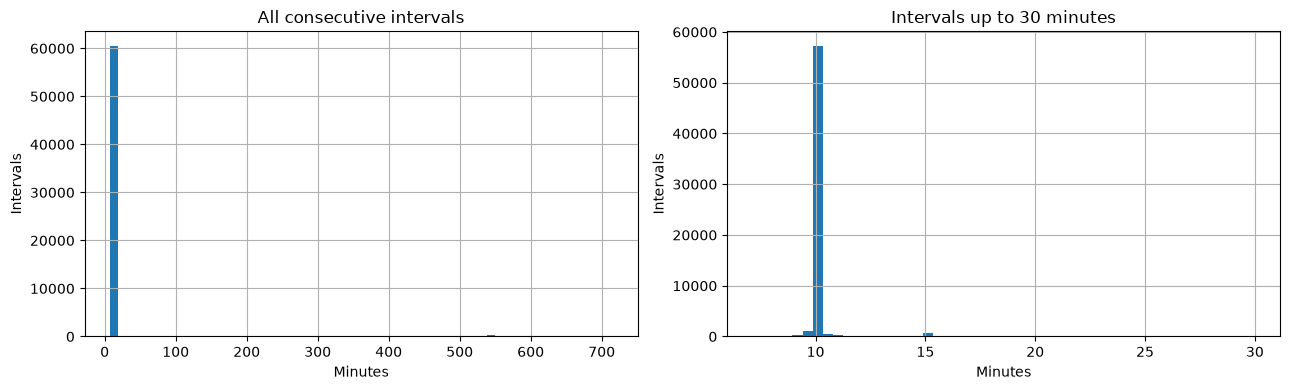

In [4]:
ordered = timed.sort_values(["camera_id", "timestamp"]).copy()
ordered["previous_timestamp"] = ordered.groupby("camera_id")["timestamp"].shift()
ordered["interval_minutes"] = (
    ordered["timestamp"] - ordered["previous_timestamp"]
).dt.total_seconds() / 60
ordered["same_date"] = (
    ordered["timestamp"].dt.normalize()
    == ordered["previous_timestamp"].dt.normalize()
)
intervals = ordered["interval_minutes"].dropna()
large_gaps = ordered.loc[ordered["interval_minutes"] > 30].copy()
within_date_gaps = large_gaps.loc[large_gaps["same_date"]]
display(intervals.describe().rename("interval_minutes").to_frame())
display(ordered.groupby("camera_id")["interval_minutes"].agg(
    ["count", "min", "median", "mean", "max"]
))
print(f"Gaps >30 minutes: {len(large_gaps):,}; "
      f"within the same date: {len(within_date_gaps):,}; "
      f"crossing dates: {(~large_gaps['same_date']).sum():,}")
display(large_gaps.nlargest(15, "interval_minutes")[
    ["camera_id", "previous_timestamp", "timestamp", "interval_minutes", "same_date"]
])
display(within_date_gaps.nlargest(15, "interval_minutes")[
    ["camera_id", "previous_timestamp", "timestamp", "interval_minutes"]
])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(intervals, bins=60)
axes[0].set(title="All consecutive intervals", xlabel="Minutes", ylabel="Intervals")
axes[1].hist(intervals[intervals <= 30], bins=50)
axes[1].set(title="Intervals up to 30 minutes", xlabel="Minutes", ylabel="Intervals")
fig.tight_layout()
display(fig)
plt.close(fig)

,observed_dates,total_images,mean_images_per_date
day_type,,,
Weekday,5,43353,8670.6
Weekend,2,17966,8983.0


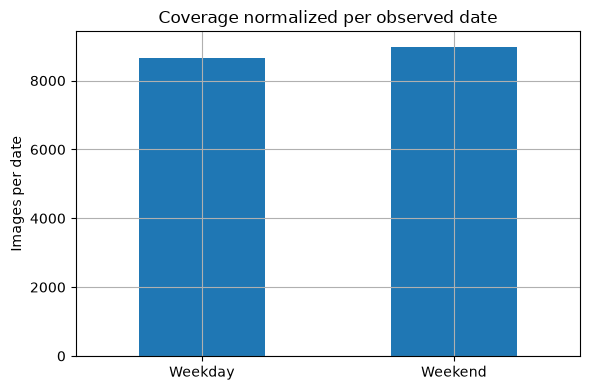

In [5]:
daily_coverage = daily_counts.to_frame()
daily_coverage["day_type"] = [
    "Weekend" if date.day_of_week >= 5 else "Weekday" for date in daily_coverage.index
]
weekday_weekend = daily_coverage.groupby("day_type").agg(
    observed_dates=("images", "size"), total_images=("images", "sum"),
    mean_images_per_date=("images", "mean"),
)
display(weekday_weekend)
fig, ax = plt.subplots(figsize=(6, 4))
weekday_weekend["mean_images_per_date"].plot.bar(ax=ax, rot=0)
ax.set(title="Coverage normalized per observed date", ylabel="Images per date",
       xlabel="")
fig.tight_layout()
display(fig)
plt.close(fig)

## 3. Spatial Exploration

Camera coordinates come from the CSV and are joined to manifest counts. Global latitude/longitude bounds identify impossible coordinates. A broad **13-14.5 degrees N, 100-101.5 degrees E** box is an explicitly approximate Bangkok-area screening rule, not an administrative boundary. Values outside it require review rather than automatic rejection.

Cameras flagged for coordinate review: 0


,camera_id,location,latitude,longitude


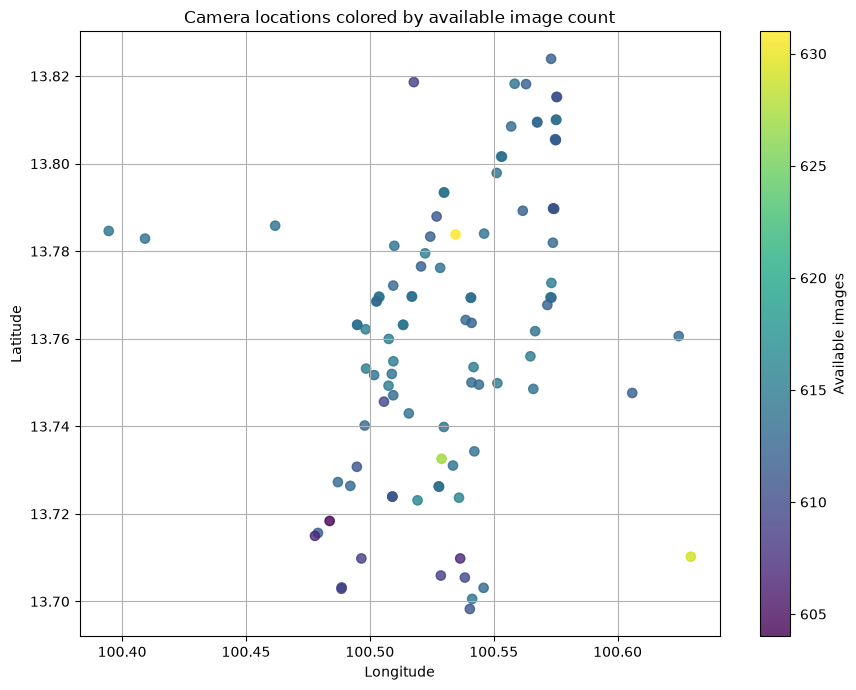

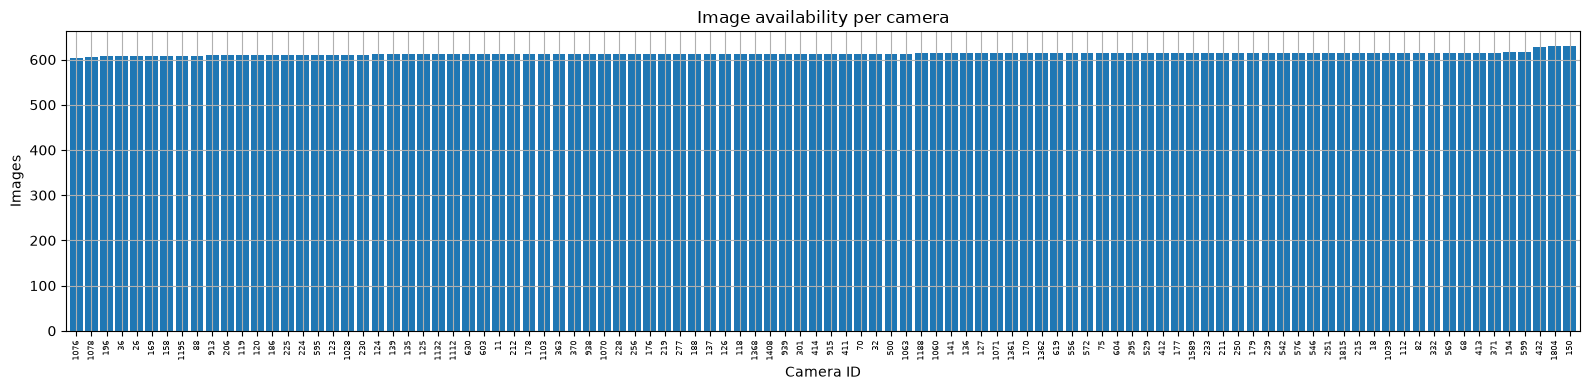

,available_images
count,100.000000
mean,613.190000
std,3.521062
min,604.000000
25%,612.000000
50%,613.000000
75%,614.000000
max,631.000000


In [6]:
camera_counts = manifest.groupby("camera_id").size().rename("available_images")
if metadata["camera_id"].duplicated().any():
    raise ValueError("CSV has duplicate camera IDs; spatial joins would be ambiguous.")
cameras = metadata.merge(camera_counts, on="camera_id", how="outer",
                         validate="one_to_one", indicator=True)
for column in ["latitude", "longitude"]:
    cameras[column] = pd.to_numeric(cameras[column], errors="coerce")
cameras["valid_global_coordinates"] = (
    cameras["latitude"].between(-90, 90)
    & cameras["longitude"].between(-180, 180)
)
cameras["within_review_box"] = (
    cameras["latitude"].between(13, 14.5)
    & cameras["longitude"].between(100, 101.5)
)
unusual_coordinates = cameras.loc[
    ~cameras["valid_global_coordinates"] | ~cameras["within_review_box"]
]
print(f"Cameras flagged for coordinate review: {len(unusual_coordinates)}")
display(unusual_coordinates[["camera_id", "location", "latitude", "longitude"]])
spatial = cameras.loc[cameras["valid_global_coordinates"]]
fig, ax = plt.subplots(figsize=(9, 7))
points = ax.scatter(spatial["longitude"], spatial["latitude"],
                    c=spatial["available_images"], s=45, cmap="viridis", alpha=.8)
ax.set(xlabel="Longitude", ylabel="Latitude",
       title="Camera locations colored by available image count")
fig.colorbar(points, ax=ax, label="Available images")
fig.tight_layout()
display(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(16, 4))
camera_counts.sort_values().plot.bar(ax=ax, width=.85)
ax.tick_params(axis="x", labelsize=6)
ax.set(title="Image availability per camera", xlabel="Camera ID", ylabel="Images")
fig.tight_layout()
display(fig)
plt.close(fig)
display(camera_counts.describe().to_frame())

## 4. Image Exploration

Use seed 42 to choose **one image per camera per observed time band**: 00-10, 11-15, and 16-23. This sample covers cameras and broad clock periods; it is not a random sample weighted by all image counts. Only sampled files are decoded, one at a time. Up to 12 thumbnails are displayed; full-resolution images are not retained in memory.

Sampled 300 images from 100 cameras.


,camera_id,timestamp,time_band,image_path,width,height,format,mode,error
0,1028,2026-08-31 08:35:53,00-10,data/raw/cctv_images/cctv_images/1028/1028_แยก...,352,288,JPEG,RGB,None
1,1028,2026-08-31 15:55:57,11-15,data/raw/cctv_images/cctv_images/1028/1028_แยก...,352,288,JPEG,RGB,None
2,1028,2026-08-30 17:35:54,16-23,data/raw/cctv_images/cctv_images/1028/1028_แยก...,352,288,JPEG,RGB,None
3,1039,2026-08-30 06:10:07,00-10,data/raw/cctv_images/cctv_images/1039/1039_ใกล...,352,288,JPEG,RGB,None
4,1039,2026-08-29 13:55:08,11-15,data/raw/cctv_images/cctv_images/1039/1039_ใกล...,352,288,JPEG,RGB,None


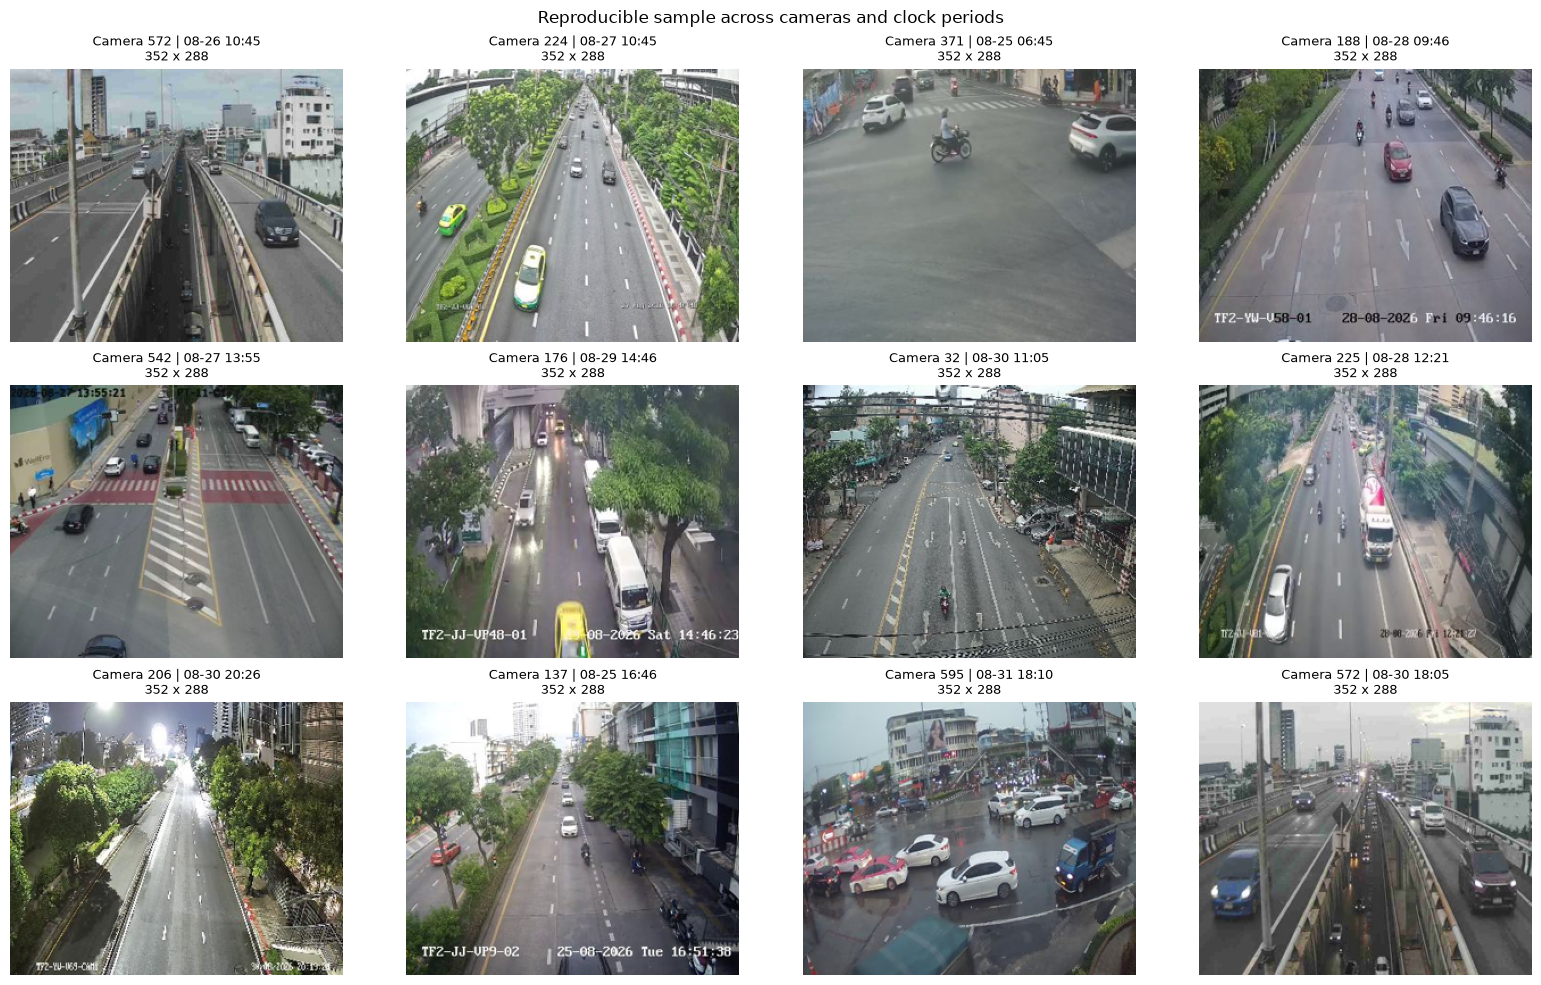

In [7]:
sample_pool = timed.copy()
sample_pool["time_band"] = pd.cut(
    sample_pool["hour"], bins=[-1, 10, 15, 23],
    labels=["00-10", "11-15", "16-23"],
)
sample_rows = (
    sample_pool.sort_values(["camera_id", "timestamp", "image_path"])
    .groupby(["camera_id", "time_band"], observed=True)
    .sample(n=1, random_state=SEED)
    .sort_values(["camera_id", "time_band"])
)
gallery = sample_rows.groupby("time_band", observed=True).sample(
    n=min(4, int(sample_rows.groupby("time_band", observed=True).size().min())),
    random_state=SEED,
)
gallery_paths = set(gallery["image_path"])
sample_records = []
thumbnails = {}
for row in sample_rows.itertuples(index=False):
    record = {"camera_id": row.camera_id, "timestamp": row.timestamp,
              "time_band": str(row.time_band), "image_path": row.image_path}
    try:
        path = (ROOT / row.image_path).resolve()
        if not path.is_relative_to(ROOT):
            raise ValueError("Image path escapes the project root")
        with Image.open(path) as image:
            record.update(width=image.width, height=image.height,
                          format=image.format, mode=image.mode)
            image.load()
            if row.image_path in gallery_paths:
                thumbnail = image.copy()
                thumbnail.thumbnail((360, 240))
                thumbnails[row.image_path] = thumbnail.convert("RGB")
        record["error"] = None
    except Exception as exc:
        record["error"] = f"{type(exc).__name__}: {exc}"
        logging.warning("Sample read failed for %s: %s", row.image_path, exc)
    sample_records.append(record)

sample_quality = pd.DataFrame(sample_records)
readable_sample = sample_quality.loc[sample_quality["error"].isna()].copy()
print(f"Sampled {len(sample_quality)} images from "
      f"{sample_quality['camera_id'].nunique()} cameras.")
display(sample_quality.head())
fig, axes = plt.subplots(3, 4, figsize=(16, 10), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, row in zip(axes.flat, gallery.itertuples(index=False)):
    if row.image_path in thumbnails:
        ax.imshow(thumbnails[row.image_path])
        quality = sample_quality.loc[sample_quality["image_path"].eq(row.image_path)].iloc[0]
        ax.set_title(f"Camera {row.camera_id} | {row.timestamp:%m-%d %H:%M}\n"
                     f"{int(quality['width'])} x {int(quality['height'])}", fontsize=9)
    else:
        ax.set_title(f"Camera {row.camera_id}: unreadable", fontsize=9)
fig.suptitle("Reproducible sample across cameras and clock periods")
fig.tight_layout()
display(fig)
plt.close(fig)
for thumbnail in thumbnails.values():
    thumbnail.close()
thumbnails.clear()

## 5. Data Quality

Completeness checks cover the manifest and CSV. Decode errors and resolution statistics cover only the sample above; successful sampling does not establish that every image is readable. Equal timestamps, repeated paths, and identical image pixels are distinct issues: this notebook checks the first two, not content duplication.

In [8]:
metadata_fields = ["location", "latitude", "longitude"]
metadata_missing = metadata[metadata_fields].isna().sum()
blank_locations = metadata["location"].astype("string").str.strip().eq("").fillna(False)
duplicate_camera_metadata = int(metadata["camera_id"].duplicated(keep=False).sum())
duplicate_records = int(manifest.duplicated().sum())
duplicate_paths = int(manifest["image_path"].duplicated().sum())
valid_timestamp_rows = manifest.dropna(subset=["timestamp"])
duplicate_camera_times = int(valid_timestamp_rows.duplicated(
    ["camera_id", "timestamp"], keep=False
).sum())
csv_ids = set(metadata["camera_id"].dropna())
image_ids = set(manifest["camera_id"].dropna())
quality_checks = pd.Series({
    "duplicate_manifest_rows_beyond_first": duplicate_records,
    "duplicate_image_paths_beyond_first": duplicate_paths,
    "rows_in_duplicate_camera_timestamp_groups": duplicate_camera_times,
    "invalid_or_missing_timestamps": int(manifest["timestamp"].isna().sum()),
    "duplicate_camera_metadata_rows": duplicate_camera_metadata,
    "blank_location_strings": int(blank_locations.sum()),
    "sampled_images": len(sample_quality),
    "unreadable_sampled_images": int(sample_quality["error"].notna().sum()),
}, name="count")
display(quality_checks.to_frame())
display(metadata_missing.rename("missing_camera_metadata").to_frame())
display(metadata.isna().sum().rename("missing_by_csv_column").to_frame())
print("Image camera IDs absent from CSV:", sorted(image_ids - csv_ids))
print("CSV camera IDs absent from images:", sorted(csv_ids - image_ids))
if "image_count" in cameras:
    expected_counts = pd.to_numeric(cameras["image_count"], errors="coerce")
    count_mismatches = cameras.loc[
        cameras["available_images"].ne(expected_counts),
        ["camera_id", "available_images", "image_count"],
    ]
    print(f"Camera image-count mismatches: {len(count_mismatches)}")
    display(count_mismatches)
display(sample_quality.loc[sample_quality["error"].notna(),
                           ["camera_id", "image_path", "error"]])

,count
duplicate_manifest_rows_beyond_first,0
duplicate_image_paths_beyond_first,0
rows_in_duplicate_camera_timestamp_groups,0
invalid_or_missing_timestamps,0
duplicate_camera_metadata_rows,0
blank_location_strings,0
sampled_images,300
unreadable_sampled_images,0


,missing_camera_metadata
location,0
latitude,0
longitude,0


,missing_by_csv_column
camera_id,0
location,0
location_detail,0
location_en,1
location_detail_en,2
latitude,0
longitude,0
ip_address,0
image_count,0


Image camera IDs absent from CSV: []
CSV camera IDs absent from images: []
Camera image-count mismatches: 0


,camera_id,available_images,image_count


,camera_id,image_path,error


,width,height,format,sampled_images
1,352,288,JPEG,296
0,348,261,JPEG,3
2,400,266,PNG,1


,sampled_images,cameras
time_band,,
00-10,100,100
11-15,100,100
16-23,100,100


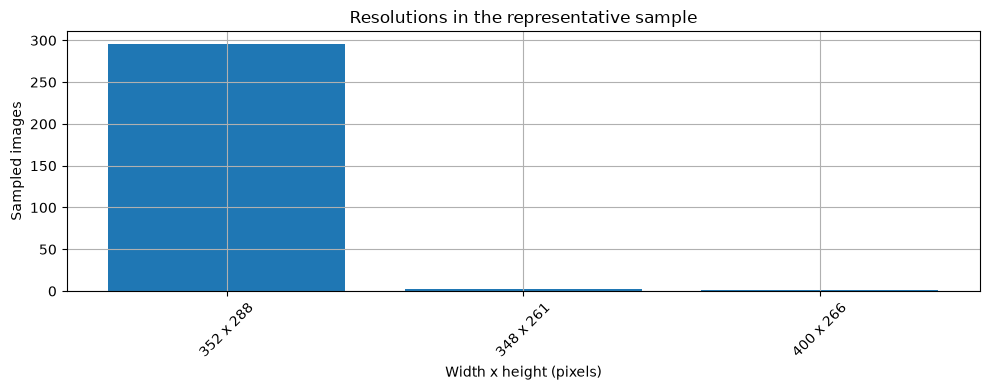

In [9]:
if not readable_sample.empty:
    resolution_counts = (
        readable_sample.groupby(["width", "height", "format"], dropna=False)
        .size().rename("sampled_images").reset_index()
        .sort_values("sampled_images", ascending=False)
    )
    display(resolution_counts)
    display(readable_sample.groupby("time_band").agg(
        sampled_images=("image_path", "size"), cameras=("camera_id", "nunique")
    ))
    fig, ax = plt.subplots(figsize=(10, 4))
    labels = (resolution_counts["width"].astype(int).astype(str) + " x "
              + resolution_counts["height"].astype(int).astype(str))
    ax.bar(labels, resolution_counts["sampled_images"])
    ax.set(title="Resolutions in the representative sample",
           xlabel="Width x height (pixels)", ylabel="Sampled images")
    ax.tick_params(axis="x", rotation=45)
    fig.tight_layout()
    display(fig)
    plt.close(fig)
else:
    resolution_counts = pd.DataFrame()
    print("No sampled images were readable; resolution analysis is unavailable.")

## 6. Key Findings

The findings below are generated from executed cells. Visual thumbnails support manual review of viewpoint, occlusion, lighting, blur, and apparent camera overlays; no detector or automated scene-quality assessment is run.

In [10]:
findings = [
    f"**Coverage:** {len(manifest):,} images from {manifest['camera_id'].nunique()} "
    f"cameras across {timed['date'].nunique()} dates, from "
    f"{timed['timestamp'].min()} to {timed['timestamp'].max()}.",
    f"**Availability by camera:** {int(camera_counts.min())}-"
    f"{int(camera_counts.max())} images; this is not a vehicle count.",
    f"**Sampling:** median consecutive interval {intervals.median():.2f} minutes; "
    f"{len(large_gaps):,} intervals exceed 30 minutes, including "
    f"{len(within_date_gaps):,} within-date gaps.",
    f"**Record quality:** {duplicate_paths} repeated image paths, "
    f"{duplicate_camera_times} rows in duplicate camera/timestamp groups, "
    f"and {manifest['timestamp'].isna().sum()} invalid/missing timestamps.",
    f"**Coordinates:** {len(unusual_coordinates)} cameras flagged by the stated "
    "global/broad-area screening rules.",
    f"**Sample quality:** {len(sample_quality)} decoded attempts across "
    f"{sample_quality['camera_id'].nunique()} cameras; "
    f"{sample_quality['error'].notna().sum()} unreadable samples and "
    f"{len(resolution_counts)} observed resolution/format combinations.",
]
display(Markdown("\n\n".join("- " + finding for finding in findings)))
display(weekday_weekend)
display(Markdown("""
**Limitations for vehicle detection**

- One observed week cannot establish seasonal or long-term traffic behavior.
- Snapshots roughly ten minutes apart cannot directly measure continuous traffic flow, track vehicles, or establish unique vehicle throughput.
- Camera availability and sampling gaps can bias comparisons. Normalize coverage before comparing model outputs.
- Per-camera viewpoint, lighting, occlusion, and scene changes need manual assessment. Resolution and successful decoding alone do not demonstrate detection suitability.
- Sample checks do not certify unsampled images. Timestamp timezone and camera clock accuracy have not been independently verified.

**Suggested Computer Vision work**

1. Review a stratified sample across cameras, dates, and clock periods; document visible quality concerns.
2. Define the target metric (for example, visible vehicles per snapshot), vehicle classes, and annotation rules.
3. Create a small manually annotated evaluation set before selecting or evaluating a detector.
4. Design camera/date-aware evaluation splits to reduce leakage between similar snapshots.
5. After evaluation, consider detection separately; preserve paths and timestamps for traceability.
"""))

- **Coverage:** 61,319 images from 100 cameras across 7 dates, from 2026-08-25 06:00:00 to 2026-08-31 21:01:19.

- **Availability by camera:** 604-631 images; this is not a vehicle count.

- **Sampling:** median consecutive interval 10.00 minutes; 671 intervals exceed 30 minutes, including 71 within-date gaps.

- **Record quality:** 0 repeated image paths, 0 rows in duplicate camera/timestamp groups, and 0 invalid/missing timestamps.

- **Coordinates:** 0 cameras flagged by the stated global/broad-area screening rules.

- **Sample quality:** 300 decoded attempts across 100 cameras; 0 unreadable samples and 3 observed resolution/format combinations.

,observed_dates,total_images,mean_images_per_date
day_type,,,
Weekday,5,43353,8670.6
Weekend,2,17966,8983.0



**Limitations for vehicle detection**

- One observed week cannot establish seasonal or long-term traffic behavior.
- Snapshots roughly ten minutes apart cannot directly measure continuous traffic flow, track vehicles, or establish unique vehicle throughput.
- Camera availability and sampling gaps can bias comparisons. Normalize coverage before comparing model outputs.
- Per-camera viewpoint, lighting, occlusion, and scene changes need manual assessment. Resolution and successful decoding alone do not demonstrate detection suitability.
- Sample checks do not certify unsampled images. Timestamp timezone and camera clock accuracy have not been independently verified.

**Suggested Computer Vision work**

1. Review a stratified sample across cameras, dates, and clock periods; document visible quality concerns.
2. Define the target metric (for example, visible vehicles per snapshot), vehicle classes, and annotation rules.
3. Create a small manually annotated evaluation set before selecting or evaluating a detector.
4. Design camera/date-aware evaluation splits to reduce leakage between similar snapshots.
5. After evaluation, consider detection separately; preserve paths and timestamps for traceability.
